In [11]:
import glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.optimize import curve_fit
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [12]:
FPS = 120
LEN_ERR_MM = 0.5     # how precisely you measured the distances in the geometry cell below

In [13]:
#PENDULUM MEASUREMENTS

mass_1 = 542.8/2
mass_2 = 194.7
mass_pivot = 58.2
mass_joint = 3.6

width = 40
length_1 = 255
length_2 = 180
dist_joint_bottom = 28
dist_joint_top = 20
dist_pivot_top = 20
size_sticker_1 = 10 #square
size_sticker_2 = 30 #triangle, equilateral
dist_sticker_1_bottom = 25
dist_sticker_1_side = 15
dist_sticker_2_side = 5

centre_sticker_1_side = dist_sticker_1_side+size_sticker_1/2
centre_sticker_1_bottom = dist_sticker_1_bottom+size_sticker_1/2
centroid_sticker_2_side = dist_sticker_2_side+size_sticker_2/2
centroid_sticker_2_bottom = 2*(np.sqrt(size_sticker_2**2-(size_sticker_2/2)**2))/3

In [14]:
#GEOMETRY USING PIVOTS AS ANCHORS

GEOM=dict(
    arm1=dict(
        length=length_1, width=width, mass=mass_1, pivot_top=dist_pivot_top,
        #distance from pivot
        sticker_centre=length_1-centre_sticker_1_bottom-dist_pivot_top,
        joint=length_1-dist_pivot_top-dist_joint_bottom,
        mass_pivot=mass_pivot,
        mass_joint=mass_joint
    ),
    arm2=dict(
        length=length_2, width=width, mass=mass_2, pivot_top=dist_joint_top,
        #distance from joint
        sticker_centre=length_2-centroid_sticker_2_bottom-dist_joint_top,
    )
)
json.dump(GEOM, open("geometry.json", "w"), indent=2)

In [15]:
def body(arm):
    """Derived quantities of one arm.
    Body frame: origin = pivot hinge, 'along' = towards the bottom edge,
    'across' = towards the camera-right side.
    Output in metres, kg, radians.
    """
    mm, g = 1e-3, 1e-3
    L, W = arm["length"], arm["width"]

    polar = lambda a, c: dict(
        along=a, across=c,
        r=np.hypot(a, c),
        delta=np.arctan2(c, a)
    )

    out = dict(stickers={})

    # Sticker centres are measured along the arm from its pivot.
    if "sticker_centre" in arm:
        name = "blue" if "mass_pivot" in arm else "red"
        out["stickers"][name] = polar(arm["sticker_centre"] * mm, 0.0)

    # Joint position relative to arm 1's pivot.
    if "joint" in arm:
        j = arm["joint"]
        if isinstance(j, dict):
            out["joint"] = polar(j["along"] * mm, j.get("across", 0.0) * mm)
        else:
            out["joint"] = polar(j * mm, 0.0)

    # Mass properties: uniform rectangular plate + point masses.
    pivot_top = arm["pivot_top"]

    parts = [(
        arm["mass"] * g,
        (L / 2 - pivot_top) * mm,
        0.0,
        arm["mass"] * g * ((L * mm)**2 + (W * mm)**2) / 12
    )]

    if "mass_pivot" in arm:
        parts.append((arm["mass_pivot"] * g, 0.0, 0.0, 0.0))

    if "mass_joint" in arm:
        j = out["joint"]
        parts.append((arm["mass_joint"] * g, j["along"], j["across"], 0.0))

    for x in arm.get("extras", []):
        parts.append((
            x["mass"] * g,
            x["along"] * mm,
            x.get("across", 0.0) * mm,
            0.0
        ))

    m = sum(p[0] for p in parts)
    ca = sum(p[0] * p[1] for p in parts) / m
    cc = sum(p[0] * p[2] for p in parts) / m

    Ip = sum(
        p[3] + p[0] * (p[1]**2 + p[2]**2)
        for p in parts
    )

    out.update(
        m=m,
        com=polar(ca, cc),
        I_pivot=Ip,
        I_cm=Ip - m * (ca**2 + cc**2)
    )

    return out


ARM = {k: body(GEOM[k]) for k in ("arm1", "arm2")}

BLUE = ARM["arm1"]["stickers"]["blue"]
RED = ARM["arm2"]["stickers"]["red"]
JOINT = ARM["arm1"]["joint"]

rows = []

for k, a in ARM.items():
    for name, s in a["stickers"].items():
        rows.append(dict(
            item=f"{k} sticker {name}",
            along_mm=s["along"] * 1e3,
            across_mm=s["across"] * 1e3,
            dist_from_pivot_mm=s["r"] * 1e3,
            angle_offset_deg=np.degrees(s["delta"])
        ))

    if "joint" in a:
        j = a["joint"]
        rows.append(dict(
            item=f"{k} hinge 2",
            along_mm=j["along"] * 1e3,
            across_mm=j["across"] * 1e3,
            dist_from_pivot_mm=j["r"] * 1e3,
            angle_offset_deg=np.degrees(j["delta"])
        ))

    c = a["com"]
    rows.append(dict(
        item=f"{k} centre of mass",
        along_mm=c["along"] * 1e3,
        across_mm=c["across"] * 1e3,
        dist_from_pivot_mm=c["r"] * 1e3,
        angle_offset_deg=np.degrees(c["delta"])
    ))

display(pd.DataFrame(rows).set_index("item").round(2))

for k, a in ARM.items():
    print(
        f"{k}: mass {a['m']*1e3:.1f} g, "
        f"I about pivot {a['I_pivot']:.3e} kg m², "
        f"I about CoM {a['I_cm']:.3e} kg m²"
    )

,along_mm,across_mm,dist_from_pivot_mm,angle_offset_deg
item,,,,
arm1 sticker blue,205.00,0.0,205.00,0.0
arm1 hinge 2,207.00,0.0,207.00,0.0
arm1 centre of mass,89.80,0.0,89.80,0.0
arm2 sticker red,142.68,0.0,142.68,0.0
arm2 centre of mass,70.00,0.0,70.00,0.0


arm1: mass 333.2 g, I about pivot 4.797e-03 kg m², I about CoM 2.111e-03 kg m²
arm2: mass 194.7 g, I about pivot 1.506e-03 kg m², I about CoM 5.516e-04 kg m²


In [16]:
runs = []

for i, f in enumerate(sorted(glob.glob("data/*.csv"))):
    d = pd.read_csv(f)

    runs.append(dict(
        name=f"run{i}",
        t=d["time_s"].to_numpy(float),
        x_blue=d["x_blue"].to_numpy(float),
        y_blue=d["y_blue"].to_numpy(float),
        x_red=d["x_red"].to_numpy(float),
        y_red=d["y_red"].to_numpy(float),
        x_hinge=np.nanmedian(d["x_hinge"]),
        y_hinge=np.nanmedian(d["y_hinge"]),
    ))

print(len(runs), "runs loaded")

25 runs loaded


In [17]:
def fit_circle(x, y):
    """Returns (cx, cy, r), their errors, residuals in px (NaN where input is NaN), angle of each point."""
    ok = np.isfinite(x) & np.isfinite(y)
    xm, ym = x[ok], y[ok]
    f = lambda xy, cx, cy, r: np.hypot(xy[0] - cx, xy[1] - cy) - r
    p0 = [xm.mean(), ym.mean(), np.hypot(xm - xm.mean(), ym - ym.mean()).mean()]
    p, cov = curve_fit(f, (xm, ym), np.zeros_like(xm), p0=p0)
    res = np.full(len(x), np.nan)
    res[ok] = f((xm, ym), *p)
    return p, np.sqrt(np.diag(cov)), res, np.arctan2(y - p[1], x - p[0])

def coverage(phi):
    return np.mean(np.histogram(phi[np.isfinite(phi)], bins=36, range=(-np.pi, np.pi))[0] > 0)

def harmonics(phi, res, n=4):
    """residual = sum of cos/sin(k*angle). k=1 centre error, k=2 ellipse (tilt), k>=3 lens/tracking."""
    ok = np.isfinite(res)
    A = np.column_stack([np.ones(ok.sum())] + [fn(k * phi[ok]) for k in range(1, n + 1) for fn in (np.cos, np.sin)])
    coef = np.linalg.lstsq(A, res[ok], rcond=None)[0]
    model = np.full(len(res), np.nan)
    model[ok] = A @ coef
    return model, np.array([np.hypot(coef[2 * k - 1], coef[2 * k]) for k in range(1, n + 1)])

def harmonic_report(runs, key, title, verbose=True):
    phi = np.concatenate([r[f"phi_{key}"] for r in runs])
    res = np.concatenate([r[f"res_{key}"] for r in runs])
    model, amps = harmonics(phi, res)
    ok = np.isfinite(res)
    noise = np.std((res - model)[ok])
    if verbose:
        print(f"{title}: harmonics k=1..4 = {amps.round(3)} px (rough 1-sigma {noise*np.sqrt(2/ok.sum()):.3f}); random noise left = {noise:.3f} px")
    return phi, res, model, noise

def plot_bias(ax, runs, key, title):
    phi, res, model, noise = harmonic_report(runs, key, title)
    edges = np.linspace(-np.pi, np.pi, 37)
    idx = np.digitize(phi, edges) - 1
    mid = np.degrees((edges[:-1] + edges[1:]) / 2)
    m = np.array([np.nanmean(res[idx == i]) if np.any(idx == i) else np.nan for i in range(36)])
    s = np.array([np.nanstd(res[idx == i]) / np.sqrt(max((idx == i).sum(), 1)) for i in range(36)])
    ax.errorbar(mid, m, s, fmt="o", ms=3)
    ok = np.isfinite(model); o = np.argsort(phi[ok])
    ax.plot(np.degrees(phi[ok][o]), model[ok][o], "r-")
    ax.axhline(0, color="k", lw=0.5)
    ax.set(title=title, xlabel="angle around fitted centre (deg)", ylabel="radial residual (px)")

def fit_ellipse(x, y):
    """Rotated ellipse. q = minor/major axis ratio; tilt = arccos(q); alpha = direction of the major axis."""
    ok = np.isfinite(x) & np.isfinite(y)
    xm, ym = x[ok], y[ok]
    c0 = np.array([xm.mean(), ym.mean()])
    w, V = np.linalg.eigh(np.cov(np.vstack([xm - c0[0], ym - c0[1]])))
    alpha0 = np.arctan2(V[1, 1], V[0, 1])
    q0 = float(np.clip(np.sqrt(w[0] / w[1]), 0.8, 0.999))
    def f(xy, cx, cy, a, q, al):
        dx, dy = xy[0] - cx, xy[1] - cy
        return np.hypot(dx * np.cos(al) + dy * np.sin(al), (-dx * np.sin(al) + dy * np.cos(al)) / q) - a
    p, cov = curve_fit(f, (xm, ym), np.zeros_like(xm), p0=[*c0, np.sqrt(2 * w[1]), q0, alpha0])
    err = np.sqrt(np.diag(cov))
    cx, cy, a, q, al = p
    if q > 1:
        a, q, al = a * q, 1 / q, al + np.pi / 2
    al = (al + np.pi / 2) % np.pi - np.pi / 2
    return dict(c=(cx, cy), q=q, alpha=al, alpha_deg=np.degrees(al), tilt_deg=np.degrees(np.arccos(min(q, 1.0))),
                tilt_err_deg=np.degrees(err[3] / max(np.sqrt(1 - q**2), 1e-6)))

def tilt_matrix(q, alpha):
    c, s = np.cos(alpha), np.sin(alpha)
    R = np.array([[c, -s], [s, c]])
    return R @ np.diag([1, 1 / q]) @ R.T

def smooth(y, n=5):
    return np.convolve(np.pad(y, (n // 2, n - 1 - n // 2), mode="edge"), np.ones(n) / n, mode="valid")

,r_px,r_err,coverage,hinge_offset_px,hinge_offset_err,noise_px,mm_per_px
run,,,,,,,
run0,375.325,0.159,0.472,6.347,0.231,1.044,0.546
run1,375.365,0.114,0.472,6.432,0.165,0.747,0.546
run2,390.373,0.058,0.556,2.062,0.083,0.807,0.525
run3,390.393,0.053,0.556,0.317,0.078,0.797,0.525
run4,390.017,0.069,0.556,0.382,0.097,0.961,0.526
run5,391.660,0.088,0.500,1.810,0.117,0.973,0.523
run6,392.382,0.079,0.472,2.649,0.109,0.902,0.522
run7,382.905,0.291,0.472,6.184,0.379,3.072,0.535
run8,381.826,0.078,0.472,5.624,0.101,0.595,0.537


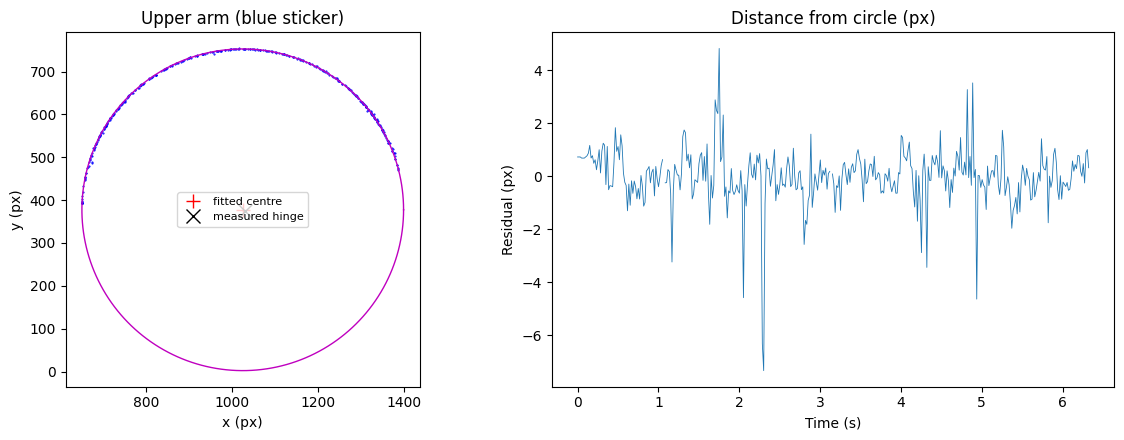

In [18]:
rows = []

for r in runs:
    pb, eb, r["res_b"], r["phi_b"] = fit_circle(
        r["x_blue"], r["y_blue"]
    )
    r["pb"] = pb

    rows.append(dict(
        run=r["name"],
        r_px=pb[2],
        r_err=eb[2],
        coverage=coverage(r["phi_b"]),
        hinge_offset_px=np.hypot(
            pb[0] - r["x_hinge"],
            pb[1] - r["y_hinge"]
        ),
        hinge_offset_err=np.hypot(eb[0], eb[1]),
        noise_px=np.nanstd(r["res_b"]),
        mm_per_px=BLUE["r"] * 1e3 / pb[2],
    ))

display(pd.DataFrame(rows).set_index("run").round(3))

r = runs[0]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
th = np.linspace(0, 2 * np.pi, 200)

# Fitted circle and measured points
ax[0].plot(r["x_blue"], r["y_blue"], "b.", ms=1)
ax[0].plot(
    r["pb"][0] + r["pb"][2] * np.cos(th),
    r["pb"][1] + r["pb"][2] * np.sin(th),
    "m-", lw=1
)
ax[0].plot(*r["pb"][:2], "r+", ms=10, label="fitted centre")
ax[0].plot(
    r["x_hinge"], r["y_hinge"],
    "kx", ms=10, label="measured hinge"
)
ax[0].set(
    aspect="equal",
    title="Upper arm (blue sticker)",
    xlabel="x (px)",
    ylabel="y (px)"
)
ax[0].legend(fontsize=8)

# Residuals from the fitted circle
ax[1].plot(r["t"], r["res_b"], lw=0.6)
ax[1].set(
    title="Distance from circle (px)",
    xlabel="Time (s)",
    ylabel="Residual (px)"
)

plt.tight_layout()
plt.show()

upper arm, raw: harmonics k=1..4 = [0.492 0.481 0.289 0.135] px (rough 1-sigma 0.020); random noise left = 1.994 px


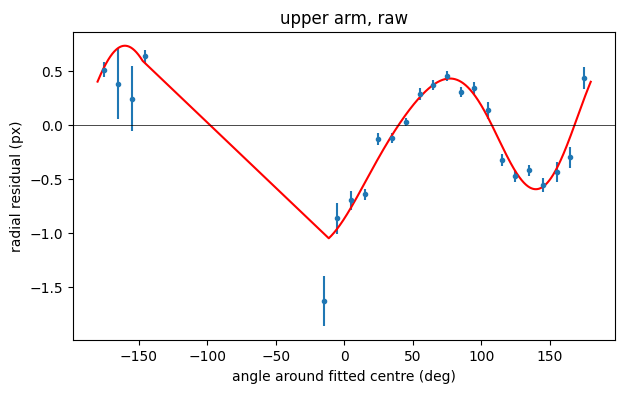

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
plot_bias(ax, runs, "b", "upper arm, raw")

In [20]:
APPLY_TILT = True
PIVOT = "hinge"       # "hinge" or "fit"
ROLL_DEG = 0.0

if PIVOT not in ("hinge", "fit"):
    raise ValueError("PIVOT must be 'hinge' or 'fit'")

pivot_of = lambda r: (
    (r["x_hinge"], r["y_hinge"])
    if PIVOT == "hinge"
    else tuple(r["pb"][:2])
)

# Estimate image-plane tilt from all runs
bx = np.concatenate([r["x_blue"] - pivot_of(r)[0] for r in runs])
by = np.concatenate([r["y_blue"] - pivot_of(r)[1] for r in runs])

e = fit_ellipse(bx, by)

print(
    f"all runs: tilt = {e['tilt_deg']:.2f} ± "
    f"{e['tilt_err_deg']:.2f} deg, q = {e['q']:.4f}, "
    f"major axis at {e['alpha_deg']:.1f} deg"
)

for r in runs:
    er = fit_ellipse(
        r["x_blue"] - pivot_of(r)[0],
        r["y_blue"] - pivot_of(r)[1]
    )
    print(
        f"  {r['name']}: tilt = {er['tilt_deg']:.2f} ± "
        f"{er['tilt_err_deg']:.2f} deg, "
        f"major axis at {er['alpha_deg']:.1f} deg"
    )

T = tilt_matrix(e["q"], e["alpha"]) if APPLY_TILT else np.eye(2)

# Pivot-relative coordinates, with tilt correction
for r in runs:
    px, py = pivot_of(r)

    for a in ("blue", "red"):
        r[f"x_{a}_c"], r[f"y_{a}_c"] = T @ np.vstack([
            r[f"x_{a}"] - px,
            r[f"y_{a}"] - py
        ])

# Rough roll estimate
est = [
    np.degrees(
        np.arctan2(
            np.nanmean(r["x_blue_c"]),
            np.nanmean(r["y_blue_c"])
        ) - BLUE["delta"]
    )
    for r in runs
]

print("\nrough roll estimate per run (deg):", np.round(est, 2),
      "<- use only if these agree")
print(
    f"applying ROLL_DEG = {ROLL_DEG:.2f} "
    "(gravity appears rotated by this angle towards +x in the image)"
)

b = np.radians(ROLL_DEG)
Rb = np.array([
    [np.cos(b), -np.sin(b)],
    [np.sin(b),  np.cos(b)]
])

for r in runs:
    for a in ("blue", "red"):
        r[f"x_{a}_f"], r[f"y_{a}_f"] = Rb @ np.vstack([
            r[f"x_{a}_c"],
            r[f"y_{a}_c"]
        ])

all runs: tilt = 8.42 ± 0.30 deg, q = 0.9892, major axis at -70.1 deg
  run0: tilt = 5.24 ± 1.49 deg, major axis at 88.0 deg
  run1: tilt = 5.03 ± 1.08 deg, major axis at 86.0 deg
  run2: tilt = 2.05 ± 0.54 deg, major axis at -30.3 deg
  run3: tilt = 4.53 ± 0.40 deg, major axis at -74.7 deg
  run4: tilt = 4.55 ± 0.58 deg, major axis at -78.0 deg
  run5: tilt = 8.29 ± 0.33 deg, major axis at 78.8 deg
  run6: tilt = 9.77 ± 0.21 deg, major axis at 79.4 deg
  run7: tilt = 19.77 ± 0.74 deg, major axis at -87.2 deg
  run8: tilt = 7.78 ± 0.27 deg, major axis at 64.4 deg
  run9: tilt = 7.92 ± 0.27 deg, major axis at 49.6 deg
  run10: tilt = 4.11 ± 0.78 deg, major axis at 34.4 deg
  run11: tilt = 3.15 ± 0.65 deg, major axis at -8.5 deg
  run12: tilt = 3.65 ± 0.47 deg, major axis at -16.2 deg
  run13: tilt = 2.81 ± 0.39 deg, major axis at -65.7 deg
  run14: tilt = 3.66 ± 0.45 deg, major axis at -78.9 deg


ValueError: `ydata` must not be empty!

In [ ]:
rows = []
for r in runs:
    pb, eb, r["res_bf"], r["phi_bf"] = fit_circle(r["x_blue_f"], r["y_blue_f"])
    rows.append(dict(run=r["name"], r_px=pb[2], r_err=eb[2], centre_offset_px=np.hypot(pb[0], pb[1]),
                     centre_err=np.hypot(eb[0], eb[1]), mm_per_px=BLUE["r"] * 1e3 / pb[2]))
table_b = pd.DataFrame(rows).set_index("run")
display(table_b.round(3))
SCALE_B = BLUE["r"] / table_b["r_px"].mean()          # metres per pixel from the upper arm

fig, ax = plt.subplots(figsize=(7, 4))
plot_bias(ax, runs, "bf", "upper arm, after correction")

In [ ]:
# Hinge 2 is not where the blue sticker is, so rebuild its position from the blue sticker:
#   angle of blue sticker = theta1 + (sticker angle offset);  hinge 2 sits at angle theta1 + (joint angle offset)
# (angles are measured in the image frame from straight down towards +x)
rows = []
for r in runs:
    psi_b = np.arctan2(r["x_blue_f"], r["y_blue_f"])
    psi_j = psi_b - BLUE["delta"] + JOINT["delta"]
    r["xj_f"] = JOINT["r"] / SCALE_B * np.sin(psi_j)
    r["yj_f"] = JOINT["r"] / SCALE_B * np.cos(psi_j)
    r["vx"], r["vy"] = r["x_red_f"] - r["xj_f"], r["y_red_f"] - r["yj_f"]     # hinge 2 -> red sticker
    pr, er, r["res_rf"], r["phi_rf"] = fit_circle(r["vx"], r["vy"])
    rows.append(dict(run=r["name"], r_px=pr[2], r_err=er[2], centre_offset_px=np.hypot(pr[0], pr[1]),
                     centre_err=np.hypot(er[0], er[1]), noise_px=np.nanstd(r["res_rf"]),
                     mm_per_px=RED["r"] * 1e3 / pr[2]))
table_r = pd.DataFrame(rows).set_index("run")
display(table_r.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
plot_bias(ax, runs, "rf", "lower arm, after correction")

In [ ]:
sc_b = table_b["mm_per_px"].to_numpy() * 1e-3
sc_r = table_r["mm_per_px"].to_numpy() * 1e-3
sd = lambda v: np.std(v, ddof=1) if len(v) > 1 else 0.0
print(f"upper arm: {sc_b.mean()*1e3:.4f} mm/px (spread between runs {sd(sc_b)*1e3:.4f})")
print(f"lower arm: {sc_r.mean()*1e3:.4f} mm/px (spread between runs {sd(sc_r)*1e3:.4f})")

SCALE = (sc_b.mean() + sc_r.mean()) / 2
fit_err = max(sd(np.r_[sc_b, sc_r]) / np.sqrt(len(sc_b) + len(sc_r)), abs(sc_b.mean() - sc_r.mean()) / 2)
SCALE_ERR = SCALE * np.hypot(fit_err / SCALE, LEN_ERR_MM / (min(BLUE["r"], RED["r"]) * 1e3))
print(f"\nPIXEL SIZE = {SCALE*1e3:.4f} ± {SCALE_ERR*1e3:.4f} mm/px  ({100*SCALE_ERR/SCALE:.2f} %)")

In [ ]:
fill = lambda a: pd.Series(a).interpolate(limit_direction="both").to_numpy()   # fill tracking gaps

for r in runs:
    xb, yb, xr, yr = (fill(r[k]) for k in ("x_blue_f", "y_blue_f", "x_red_f", "y_red_f"))   # px, y down
    r["Xblue"], r["Yblue"] = xb * SCALE, -yb * SCALE         # metres, relative to hinge 1, y UP
    r["Xred"], r["Yred"] = xr * SCALE, -yr * SCALE

    r["th1"] = np.unwrap(np.arctan2(xb, yb)) - BLUE["delta"]   # arm 1 angle from straight down
    psi_j = r["th1"] + JOINT["delta"]
    xj, yj = JOINT["r"] * np.sin(psi_j), JOINT["r"] * np.cos(psi_j)   # hinge 2, metres, y down
    r["Xjoint"], r["Yjoint"] = xj, -yj

    r["th2"] = np.unwrap(np.arctan2(xr * SCALE - xj, yr * SCALE - yj)) - RED["delta"]   # arm 2 angle from straight down

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for r in runs:
    ax[0].plot(r["t"] - r["t"][0], r["th1"], lw=0.8, label=r["name"])
    ax[1].plot(r["t"] - r["t"][0], r["th2"], lw=0.8)
ax[0].set(title="arm 1 angle θ₁ (rad)", xlabel="t (s)"); ax[1].set(title="arm 2 angle θ₂ (rad)", xlabel="t (s)")
ax[0].legend(fontsize=7)

In [ ]:
# Noise floor of the run-to-run distance. Random scatter left after removing the systematic parts:
_, _, _, sigma_b = harmonic_report(runs, "bf", "", verbose=False)       # blue sticker, px per coordinate
_, _, _, sigma_v = harmonic_report(runs, "rf", "", verbose=False)       # lower-arm circle (red + error of rebuilt hinge 2)
leak = 0.5 * (sigma_b * JOINT["r"] / BLUE["r"]) ** 2                    # hinge-2 error, from blue noise, seen along the red radius
sigma_r = np.sqrt(max(sigma_v**2 - leak, 0))                            # red sticker, px per coordinate
floor_m = 2 * np.sqrt(sigma_b**2 + sigma_r**2) * SCALE
print(f"blue sticker noise ~ {sigma_b:.3f} px = {sigma_b*SCALE*1e3:.3f} mm per coordinate")
print(f"red sticker noise  ~ {sigma_r:.3f} px = {sigma_r*SCALE*1e3:.3f} mm per coordinate")
print(f"\nNOISE FLOOR for the run-to-run distance ~ {floor_m*1e3:.3f} mm")

In [ ]:
t_end = min(r["t"][-1] - r["t"][0] for r in runs)
grid = np.arange(0, t_end, 1 / FPS)
keys = ("Xblue", "Yblue", "Xred", "Yred")
G = [{k: np.interp(grid, r["t"] - r["t"][0], r[k]) for k in keys} for r in runs]
pairs = list(combinations(range(len(G)), 2))
dist = {p: np.sqrt(sum((G[p[0]][k] - G[p[1]][k]) ** 2 for k in keys)) for p in pairs}   # metres

n0 = max(5, int(0.3 * FPS))
sat = np.median(np.concatenate([d[int(0.8 * len(grid)):] for d in dist.values()]))
early = np.median(np.concatenate([d[:n0] for d in dist.values()]))
print(f"saturation = {sat*1e3:.1f} mm, noise floor = {floor_m*1e3:.3f} mm, median distance in first 0.3 s = {early*1e3:.3f} mm")

rows = []
for p, d in dist.items():
    ds = smooth(d)
    lo = np.where(ds > 3 * floor_m)[0]            # growth starts: clearly above noise
    hi = np.where(ds > 0.3 * sat)[0]              # growth ends: approaching saturation
    lam = np.nan
    if len(lo) and len(hi) and hi[0] - lo[0] >= 8:
        lam = np.polyfit(grid[lo[0]:hi[0]], np.log(ds[lo[0]:hi[0]]), 1)[0]
    above = np.where(ds > 0.1 * sat)[0]
    rows.append(dict(run_a=runs[p[0]]["name"], run_b=runs[p[1]]["name"], d_start_mm=d[:n0].mean() * 1e3,
                     t_diverge_s=grid[above[0]] if len(above) else np.nan, lambda_per_s=lam))
res_tab = pd.DataFrame(rows)
display(res_tab.round(3))
lam = res_tab["lambda_per_s"]
print(f"Largest Lyapunov exponent = {lam.median():.2f} 1/s (median; mean {lam.mean():.2f} ± {lam.std():.2f}); "
      f"distance grows by e every {1/lam.median():.2f} s")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
t_sat = grid[np.argmax(np.median(list(dist.values()), axis=0) > 0.5 * sat)]
for a in ax:
    for p, d in dist.items():
        a.semilogy(grid, d * 1e3, lw=0.8, alpha=0.7)
    a.axhline(floor_m * 1e3, color="r", ls=":", label="noise floor")
    a.set(xlabel="t (s)", ylabel="d (mm)")
ax[0].axhline(sat * 1e3, color="k", ls=":", label="saturation"); ax[0].set(title="distance between runs (all pairs)"); ax[0].legend()
ax[1].set(title="zoom on the growth phase", xlim=(0, max(2 * t_sat, 1)))
fig.tight_layout()